## 1、为什么需要记忆

记忆是一种记住之前互动信息的系统。随着Agent处理涉及大量用户交互的复杂任务，记忆变得至关重要！

大多数的大模型应用程序都会有一个 会话接口 ，允许我们进行 多轮的对话 ，并有一定的上下文记忆能力。

但实际上，大模型本身是“无状态”的， 不会记忆 任何上下文的。即每次调用 agent.invoke() 都是全新的开始，不记得之前的对话。

我们希望的智能体应该是右图的情况：

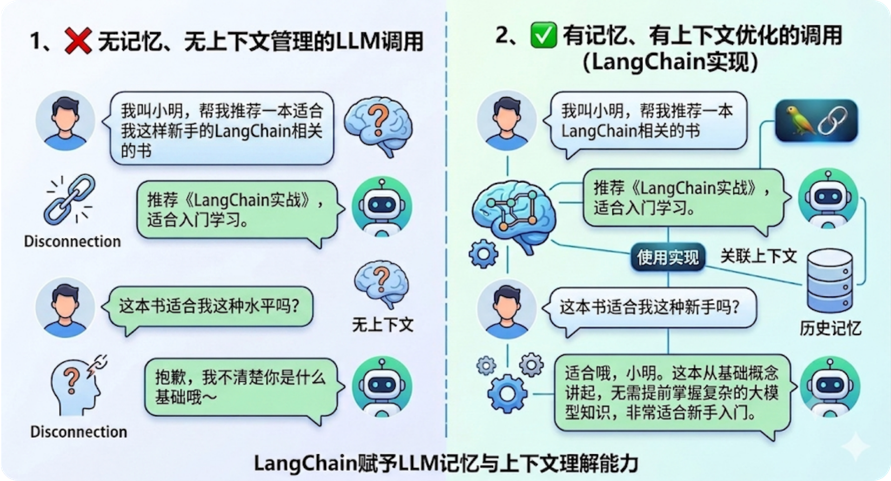

## 2、如何解决记忆问题

### 2.1 上下文工程

实现记忆功能，需要额外的模块去保存我们和模型对话的上下文信息，然后在下一次请求时，把历史信息都输入给模型，让模型输出结果。

在LangChain中，记忆（Memory）就是专门负责存储历史交互信息的组件，核心作用时保存上下文和提供上下文，在LLM在每次响应时，都能看到之前的对话内容。

上下文工程（Context Engineering）负责合理组织这些记忆和任务信息，让LLM的响应更连贯、更贴合需求。这也是Agent能实现复杂多轮交互的核心基础。

类比：

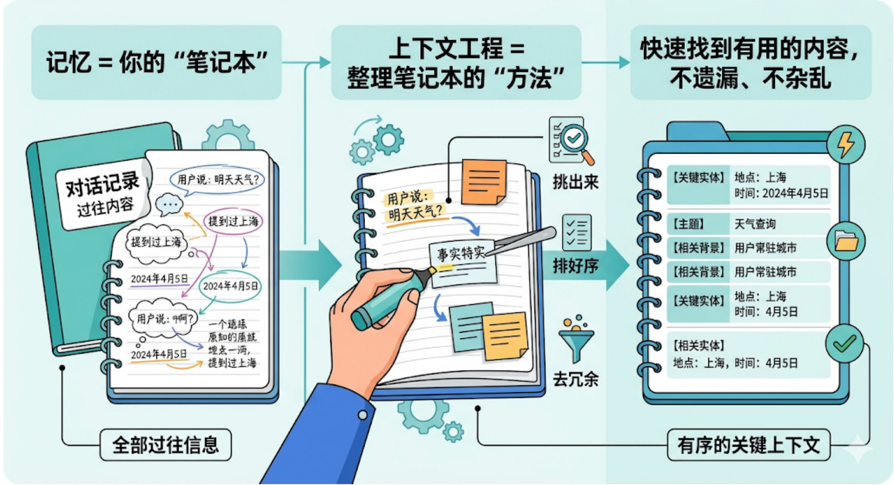

举例：

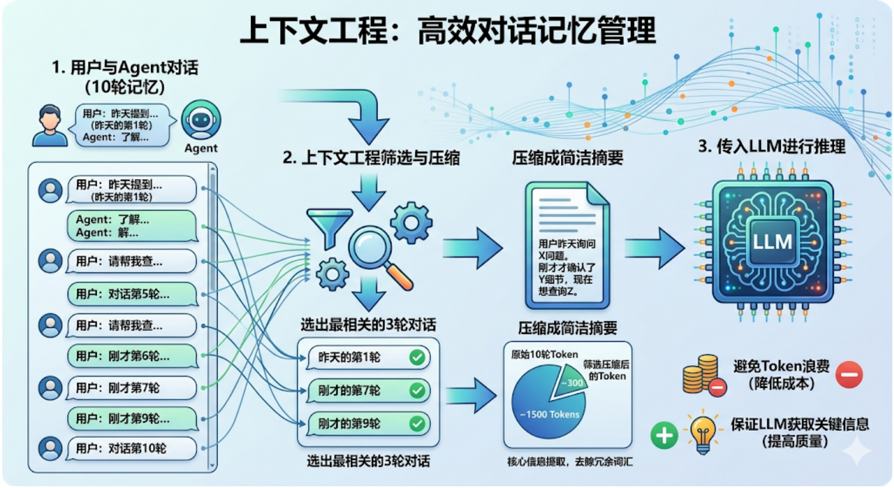

### 2.2 上下文类型及相关的API

LangChain的上下文工程是基于Agent讨论的，而上下文工程是构建在LangGraph之上的。

LangGraph 提供了三种管理上下文的方法，这些方法结合了可变性和生命周期维度：

| 上下文类型     | 描述                            | 可变性  | 生命周期  | 访问方法                |
|:----------|:------------------------------|:-----|:------|:--------------------|
| 动态运行时上下文  | 在单次运行中会演变的可变数据                | 动态   | 单次运行  | LangGraph state对象   |
| 动态跨会话上下文  | 在对话间共享的持久数据。比如用户偏好、历史洞察、知识条目  | 动态   | 跨会话   | LangGraph store对象   |
| 静态运行时上下文  | 在启动时传入的用户元数据、工具、数据库连接         | 静态   | 单次运行  | LangGraph context对象 |

## 3、LangChain的记忆

### 3.1 记忆的分类

官方文档：https://docs.langchain.com/oss/python/concepts/memory

记忆分为短期记忆和长期记忆，对应不同的使用场景：
- 短期记忆（Short-term memory、会话级记忆、thread-scoped memory）：作用范围是单个对话线程（Thread）内，一旦开启新会话（更换thread_id），记忆就消失。
- 长期记忆（Long-term memory，跨会话级记忆）：在会话间存储用户特定或应用级数据，并在会话线程间共享。它可以随时在任何线程中被调用。记忆的范围是任意自定义命名空间，而不仅仅是单一线程ID。

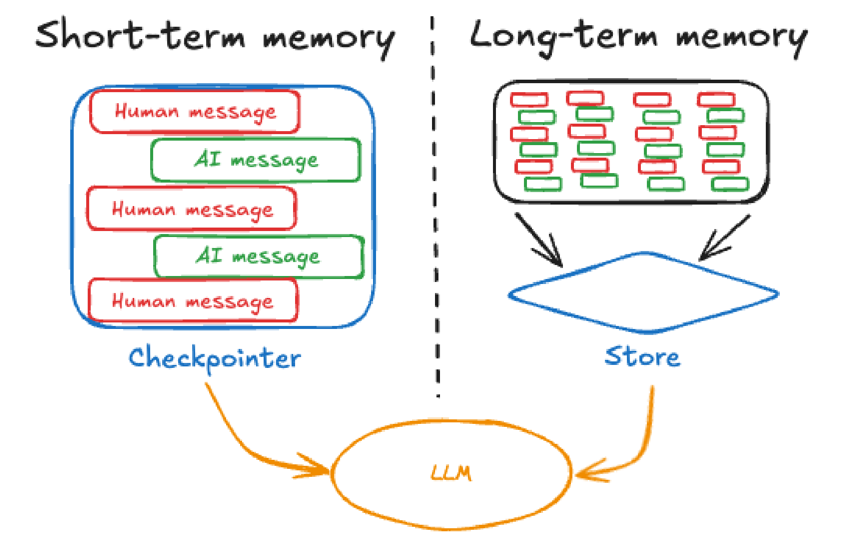

### 3.2 记忆的管理

在LangChain v0.x版本中，通过专用的xxxMemory类管理记忆。

在LangChain v1.x版本中，Agent是构建在LangGraph图结构之上的，通过上文提到的state和store构建记忆系统。使用更简单、功能更统一。
- state：**短期记忆对象**，以会话为单位组织，包含当前会话的所有消息记录以及自定义信息。
- store：**长期记忆对象**，跨会话持久化的数据，通常需要结合向量数据库或外部存储实现。